# A 4D time-series viewer you can talk to

**4D data** = a 3D field that changes in time, f(t, x, y, z). This is the same kind of data
as the 4D time-series visualization from the Jalali-lab work. A screen is 2D, so a viewer
shows it through windows: slices, projections, point probes, isosurfaces, and animation.

**Natural language:** type "show the z slice at 0.5 at t = 2 fs" and the viewer works out
*what* you want (the intent) and *with which numbers* (the slots). The NLP here is classic
and fully inspectable: a bag-of-words **Naive Bayes** classifier plus regular-expression
slot filling. No large language model is used, so every decision can be traced and tested.

**The dataset is real physics (Knight Ch. 40):** an electron in a 1 nm rigid 3D box, in an
equal superposition of the (1,1,1) and (2,1,1) states. Its probability cloud sloshes left
and right with period h/(E₂₁₁ − E₁₁₁) ≈ 3.67 fs.

Modules: `dgs/viewer4d.py`, `dgs/nl_commands.py` (tests: `tests/test_viewer4d_nlp.py`).

In [1]:
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import sympy as sp
sp.init_printing(use_unicode=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import display, HTML

from dgs import viewer4d as V, nl_commands as NL, one_d_quantum as Q
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
vs = V.box_superposition(L=1.0, n=32, frames=41)
print("data shape (T, Nx, Ny, Nz):", vs.data.shape, f"= {vs.data.size:,} numbers")

data shape (T, Nx, Ny, Nz): (41, 32, 32, 32) = 1,343,488 numbers


## 1. The 4D dataset and its checks

$$\psi(x,y,z,t) = \tfrac{1}{\sqrt2}\left[\psi_{111}\,e^{-iE_{111}t/\hbar} + \psi_{211}\,e^{-iE_{211}t/\hbar}\right], \qquad f = |\psi|^2.$$

The cross term oscillates as cos(ΔE·t/ħ). That is the "slosh". The center of mass along x
follows ⟨x⟩(t) = L/2 + ⟨1|x|2⟩ cos(ΔE·t/ħ), with ⟨1|x|2⟩ = −16L/(9π²). SymPy computes that
matrix element below.

normalization at every frame, min/max: 1.0 1.0
beat period = 3.666 fs;  first and last frames equal: True


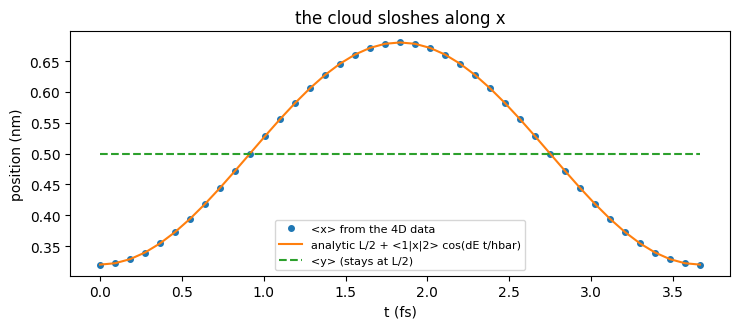

In [2]:
x, L = sp.symbols("x L", positive=True)
p1 = sp.sqrt(2 / L) * sp.sin(sp.pi * x / L); p2 = sp.sqrt(2 / L) * sp.sin(2 * sp.pi * x / L)
X12 = sp.simplify(sp.integrate(p1 * x * p2, (x, 0, L)))
display(sp.Eq(sp.Symbol("<1|x|2>"), X12))

dV = (vs.x[1] - vs.x[0])**3
print("normalization at every frame, min/max:", (vs.data.sum(axis=(1, 2, 3)) * dV).min().round(12), (vs.data.sum(axis=(1, 2, 3)) * dV).max().round(12))
print(f"beat period = {vs.t[-1]:.3f} fs;  first and last frames equal: {np.allclose(vs.data[0], vs.data[-1])}")
com = vs.center_of_mass()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(vs.t, com[:, 0], "o", ms=4, label="<x> from the 4D data")
ax.plot(vs.t, 0.5 + float(X12.subs(L, 1)) * np.cos(2 * np.pi * vs.t / vs.t[-1]), label="analytic L/2 + <1|x|2> cos(dE t/hbar)")
ax.plot(vs.t, com[:, 1], "--", label="<y> (stays at L/2)")
ax.set_xlabel("t (fs)"); ax.set_ylabel("position (nm)"); ax.legend(fontsize=8); ax.set_title("the cloud sloshes along x")
plt.tight_layout(); plt.show()

## 2. Four windows into 4D

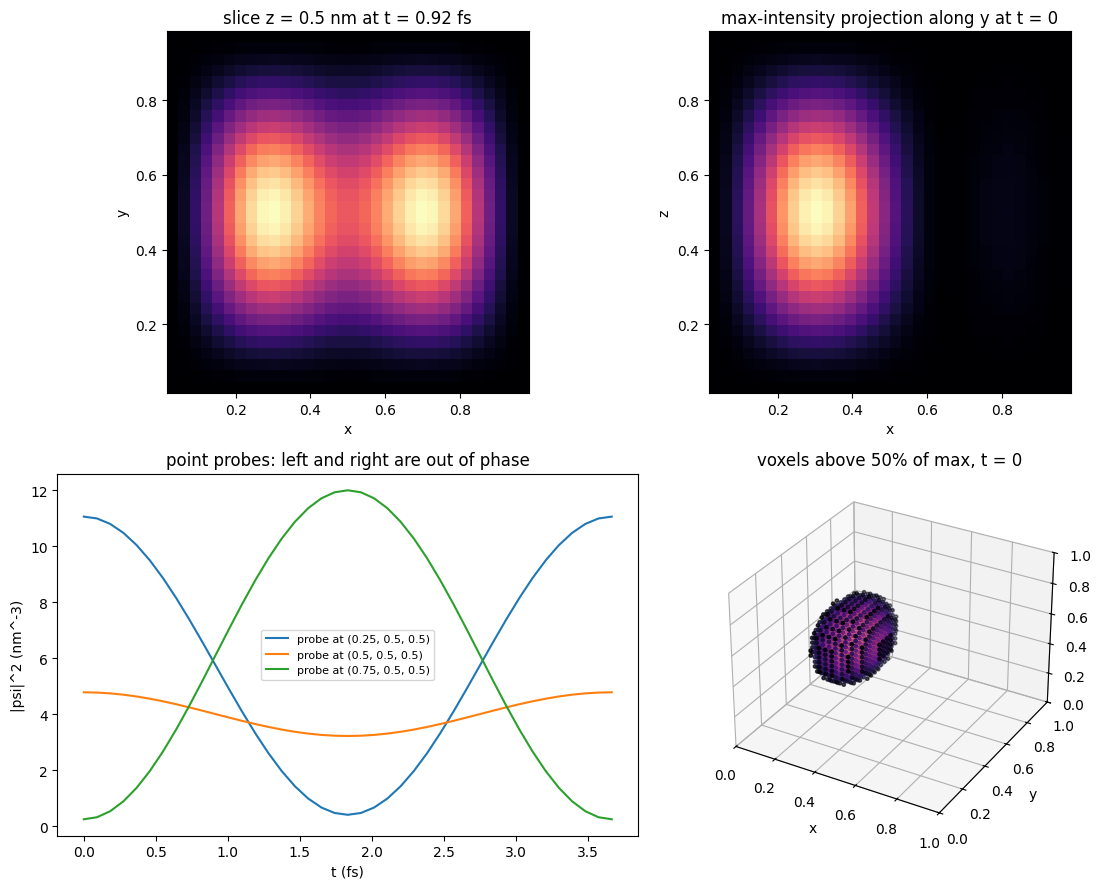

In [3]:
def extent(hv):
    a, b = vs.axis(hv[0]), vs.axis(hv[1])
    return [a[0], a[-1], b[0], b[-1]]

t_show = vs.t[10]                              # a quarter period
fig = plt.figure(figsize=(12, 9))
ax1 = fig.add_subplot(2, 2, 1)
img, hv = vs.slice("z", 0.5, t_show)
ax1.imshow(img.T, origin="lower", extent=extent(hv), cmap="magma"); ax1.set_xlabel(hv[0]); ax1.set_ylabel(hv[1])
ax1.set_title(f"slice z = 0.5 nm at t = {t_show:.2f} fs")
ax2 = fig.add_subplot(2, 2, 2)
img, hv = vs.projection("y", 0.0, "max")
ax2.imshow(img.T, origin="lower", extent=extent(hv), cmap="magma"); ax2.set_xlabel(hv[0]); ax2.set_ylabel(hv[1])
ax2.set_title("max-intensity projection along y at t = 0")
ax3 = fig.add_subplot(2, 2, 3)
for pt in [(0.25, 0.5, 0.5), (0.5, 0.5, 0.5), (0.75, 0.5, 0.5)]:
    ax3.plot(vs.t, vs.probe(pt), label=f"probe at {pt}")
ax3.set_xlabel("t (fs)"); ax3.set_ylabel(vs.name); ax3.legend(fontsize=8); ax3.set_title("point probes: left and right are out of phase")
ax4 = fig.add_subplot(2, 2, 4, projection="3d")
pts, vals = vs.isosurface_points(0.0, 0.5)
ax4.scatter(*pts.T, c=vals, cmap="magma", s=6); ax4.set_xlim(0, 1); ax4.set_ylim(0, 1); ax4.set_zlim(0, 1)
ax4.set_xlabel("x"); ax4.set_ylabel("y"); ax4.set_zlabel("z"); ax4.set_title("voxels above 50% of max, t = 0")
plt.tight_layout(); plt.show()

## 3. The NLP, step by step

**Tokens:** lowercase words, with numbers replaced by `<num>`, plus bigrams (word pairs) so
"along_z" and "xy_plane" count as features. **Naive Bayes:** each intent has a word
distribution learned from example phrases. A new phrase gets the intent with the highest
log P(intent) + Σ log P(word | intent). Laplace smoothing (+1) keeps unseen words from
zeroing a class.

In [4]:
print("tokens:", NL.tokenize("Show the xy plane at z = 0.3 at t = 2 fs"))
m = NL.MODEL
print(f"\n{len(m.classes)} intents, {sum(len(v) for v in NL.TRAINING.values())} training phrases, vocabulary {len(m.vocab)} tokens")

V_ = len(m.vocab)
rows = []
for c in m.classes:
    lp = {w: math.log((m.counts[c][w] + 1) / (m.total[c] + V_)) for w in m.vocab}
    other = {w: np.mean([math.log((m.counts[o][w] + 1) / (m.total[o] + V_)) for o in m.classes if o != c]) for w in m.vocab}
    top = sorted(m.vocab, key=lambda w: lp[w] - other[w], reverse=True)[:6]
    rows.append((c, ", ".join(top)))
display(pd.DataFrame(rows, columns=["intent", "most telling tokens (log-likelihood ratio)"]))

tokens: ['show', 'the', 'xy', 'plane', 'at', 'z', '<num>', 'at', 't', '<num>', 'fs', 'show_the', 'the_xy', 'xy_plane', 'plane_at', 'at_z', 'z_<num>', '<num>_at', 'at_t', 't_<num>', '<num>_fs']

7 intents, 77 training phrases, vocabulary 324 tokens


,intent,most telling tokens (log-likelihood ratio)
0,animate,"animate, animate_the, slice, slice_at, play, the_slice"
1,center,"center, position, mass, centroid, the_center, center_of"
2,isosurface,"<num>_d, d, above, <num>, <num>_percent, percent"
3,peak,"when, peak, is_the, is, and, find"
4,probe,"<num>_<num>, point, <num>, the_point, point_<num>, <num>_y"
5,projection,"along, along_y, along_z, projection, sum, sum_along"
6,slice,"cut, at, slice, plane, x_at, plane_at"


In [5]:
from tests.test_viewer4d_nlp import HELD_OUT
classes = NL.MODEL.classes
cm = pd.DataFrame(0, index=classes, columns=classes)
for text, want in HELD_OUT:
    cm.loc[want, NL.parse(text).intent] += 1
acc = np.trace(cm.values) / cm.values.sum()
print(f"held-out phrases (never seen in training): accuracy {acc:.0%} ({np.trace(cm.values)}/{cm.values.sum()})")
display(cm.rename_axis(index="true", columns="predicted"))
print("A tiny held-out set like this is a smoke test, not a benchmark: 14 phrases can't measure real-world accuracy.")

held-out phrases (never seen in training): accuracy 100% (14/14)


predicted,animate,center,isosurface,peak,probe,projection,slice
true,,,,,,,
animate,2,0,0,0,0,0,0
center,0,2,0,0,0,0,0
isosurface,0,0,2,0,0,0,0
peak,0,0,0,2,0,0,0
probe,0,0,0,0,2,0,0
projection,0,0,0,0,0,2,0
slice,0,0,0,0,0,0,2


A tiny held-out set like this is a smoke test, not a benchmark: 14 phrases can't measure real-world accuracy.


## 4. The command console

Each command is parsed, shown with its intent, confidence and slots, and then drawn.
Missing slots get defaults (t = 0, axis z, the middle of the box). Gibberish is
**refused, not guessed**.

,command,intent,confidence,slots
0,show the z slice at z = 0.5 at t = 0.9 fs,slice,1.00,"{'t': 0.9, 'axis': 'z', 'position': 0.5, 'view': 'slice'}"
1,max projection along y at time 1.8,projection,0.97,"{'t': 1.8, 'axis': 'y', 'view': 'projection'}"
2,"probe the point (0.25, 0.5, 0.5)",probe,1.00,"{'point': (0.25, 0.5, 0.5)}"
3,isosurface at 60% at 1.8 fs,isosurface,0.71,"{'t': 1.8, 'level': 0.6, 'view': 'isosurface'}"
4,track the center of mass,center,1.00,{}
5,when and where does it peak,peak,1.00,{}
6,purple monkey dishwasher,(not understood),0.21,{}


> when and where does it peak
  peak 12.33 at t = 0 fs, (x, y, z) = (0.297, 0.484, 0.484)
> purple monkey dishwasher
  Not sure what you meant (best guess 'animate', 21%). Try e.g. 'z slice at 0.5 at t = 1 fs'.


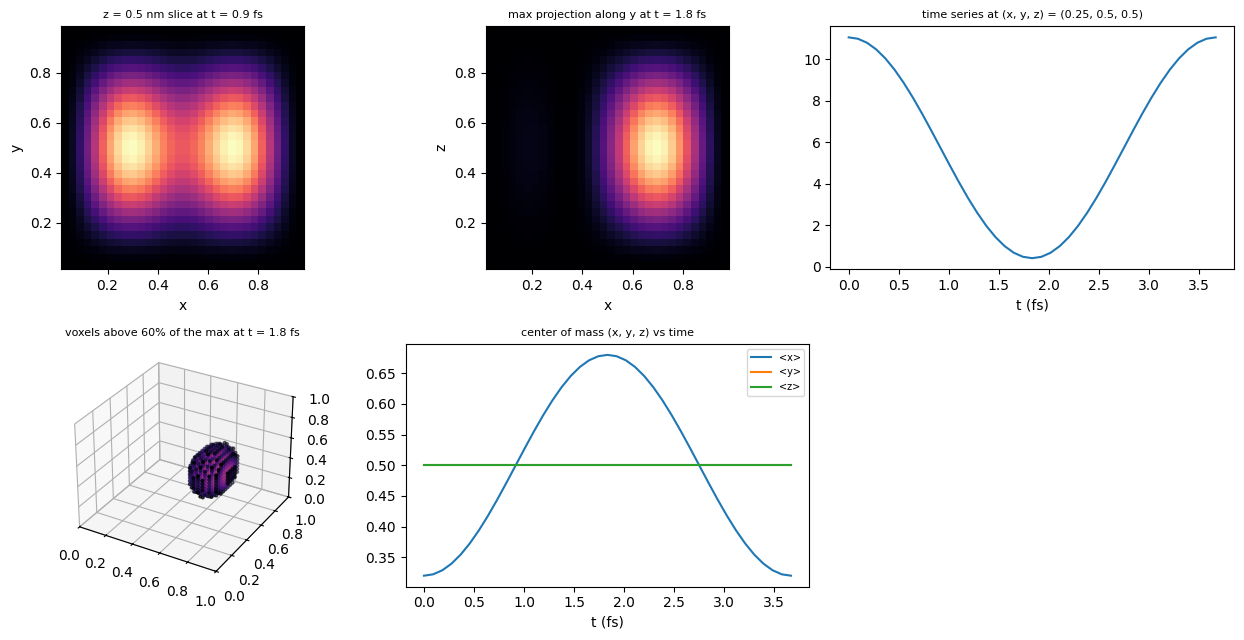

In [6]:
commands = [
    "show the z slice at z = 0.5 at t = 0.9 fs",
    "max projection along y at time 1.8",
    "probe the point (0.25, 0.5, 0.5)",
    "isosurface at 60% at 1.8 fs",
    "track the center of mass",
    "when and where does it peak",
    "purple monkey dishwasher",
]
parsed = [NL.parse(c) for c in commands]
display(pd.DataFrame([(c.text, c.intent if c.understood else "(not understood)", round(c.confidence, 2), c.slots) for c in parsed],
                     columns=["command", "intent", "confidence", "slots"]))

def show(result, ax):
    k = result["kind"]
    if k == "image":
        ax.imshow(result["image"].T, origin="lower", extent=extent(result["axes"]), cmap="magma")
        ax.set_xlabel(result["axes"][0]); ax.set_ylabel(result["axes"][1])
    elif k == "series":
        ax.plot(result["x"], result["y"]); ax.set_xlabel("t (fs)")
    elif k == "series3":
        for i, a in enumerate("xyz"):
            ax.plot(result["x"], result["y"][:, i], label=f"<{a}>")
        ax.legend(fontsize=7); ax.set_xlabel("t (fs)")
    elif k == "points":
        ax.scatter(*result["points"].T, c=result["values"], cmap="magma", s=4)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_zlim(0, 1)
    ax.set_title(result["text"], fontsize=8)

results = [NL.execute(vs, c) for c in parsed]
for cmd, res in zip(parsed, results):
    if res["kind"] in ("answer", "unknown"):
        print(f"> {cmd.text}\n  {res['text']}")
graphics = [r for r in results if r["kind"] not in ("answer", "unknown")]
fig = plt.figure(figsize=(13, 6.5))
for i, res in enumerate(graphics):
    ax = fig.add_subplot(2, 3, i + 1, projection="3d" if res["kind"] == "points" else None)
    show(res, ax)
plt.tight_layout(); plt.show()

In [7]:
# "animate the z slice at 0.5": the animate intent, drawn as an embedded animation
cmd = NL.parse("animate the z slice at z = 0.5")
res = NL.execute(vs, cmd)
print(cmd.intent, round(cmd.confidence, 2), res["text"])
if res["kind"] != "animation":
    raise RuntimeError(f"expected an animate command, got {cmd.intent!r}; add training phrases and re-run")
plt.rcParams["animation.embed_limit"] = 30
fig, ax = plt.subplots(figsize=(4, 3.6), dpi=70)
img0, hv = vs.slice(res["axis"], res["position"], vs.t[0])
im = ax.imshow(img0.T, origin="lower", extent=extent(hv), cmap="magma", vmin=0, vmax=vs.data.max())
ax.set_xlabel(hv[0]); ax.set_ylabel(hv[1]); ttl = ax.set_title("")

def frame(n):
    im.set_data(vs.slice(res["axis"], res["position"], vs.t[n])[0].T)
    ttl.set_text(f"z = {res['position']} nm slice, t = {vs.t[n]:.2f} fs")
    return im, ttl

anim = animation.FuncAnimation(fig, frame, frames=range(0, len(vs.t), 2), interval=120)
html = anim.to_jshtml(); plt.close(fig)
HTML(html)

animate 0.99 animate the slice (z) over 41 frames


## 5. Limits, and where this could go

* **The parser only knows what it was shown:** about 75 training phrases. Unusual wording can
  fail. When that happens, add phrases (more data), not special cases.
* **Slots are regular expressions:** "a third of the way along x" won't parse. A large
  language model could map free text to the same `Command` structure. Classic NLP is still
  the baseline to test it against.
* **Bigger data:** the views are NumPy slices, so a (100, 256, 256, 256) volume works the
  same way, only slower. Export with `np.save` for ParaView or a WebXR viewer when you want true 3D.

## Practice (my own problems)

1. Which intent and slots should "sum along z at 3 fs" produce? Check with `NL.parse`.
2. Why does the probe at x = 0.25 peak when the probe at x = 0.75 is at a minimum?
3. Change the superposition to (1,1,1) + (1,2,1). Along which axis does the cloud slosh now, and with what period?
4. Write a phrase that the classifier gets wrong. Then fix it by adding one training phrase, and re-run the tests.

In [8]:
c = NL.parse("sum along z at 3 fs"); print("1.", c.intent, c.slots)
print("2. the cross term is psi_111 * psi_211 ~ sin(pi x) sin(2 pi x), which changes sign at x = L/2: left and right swap")
vs2 = V.box_superposition(states=((1, 1, 1), (1, 2, 1)), n=24, frames=21)
com2 = vs2.center_of_mass()
print(f"3. sloshes along y (range of <y>: {np.ptp(com2[:, 1]):.3f} nm, of <x>: {np.ptp(com2[:, 0]):.1e} nm), same period {vs2.t[-1]:.3f} fs (same energy gap)")

1. projection {'t': 3.0, 'axis': 'z', 'kind': 'sum', 'view': 'projection'}
2. the cross term is psi_111 * psi_211 ~ sin(pi x) sin(2 pi x), which changes sign at x = L/2: left and right swap
3. sloshes along y (range of <y>: 0.360 nm, of <x>: 1.7e-16 nm), same period 3.666 fs (same energy gap)


## Checklist

- [ ] 4D = f(t, x, y, z). View it through slices, projections (max or sum), probes, isosurfaces, and animation.
- [ ] Check the data before trusting the views: normalization, period, and center of mass against the analytic answer.
- [ ] NLP = intent classification + slot filling. Naive Bayes: log prior + Σ log likelihood, with Laplace smoothing.
- [ ] Measure the parser on held-out phrases. Refuse low-confidence input instead of guessing.